# Figure 5 Supplement 3: Low- vs. high-SNR bounds in the predefined-bound task

The analysis of Figure 5's top row (blocked SNR) for the predefined-bound (PD) task, in which the
participant sets the bound before each trial (blocks 1–3 at low SNR, blocks 4–6 at high SNR, each a single
SNR, in the same three penalty conditions).

**Each panel** (one per penalty condition): the reward rate of every pair of fixed low- and high-SNR
bounds (heatmap, coins per step), the near-optimal pairs (dotted red contour: reward rate ≥ 95% of the panel's
maximum; no single optimum is marked, because the surfaces are nearly flat near their peak), each
participant's mean low- and high-SNR bound (white circles; triangles: beyond the panel edge, bound > 0.78),
the participants' median (large black circle)
and the Wilcoxon signed-rank p of hi − lo (upper left). The median difference, the hi/lo ratio and the
Spearman correlation of lo and hi are in the tables below.

**Bounds:** mean |bound| per participant and block over trials with trial_number ≥ 10 on which the pigeon
reached the set bound (as in Figure04S01): trials with no choice (aborted by a key press, or the block's
step budget ran out) are left out; wall-hit and one-step trials are kept, since the bound is set, not
measured.

**Reward-rate surfaces:** mean coins over a grid of fixed bounds (`get_simulated_data_table`: 300
simulated participants per bound, PD's 800-step blocks and the block's reward rules, `BLOCK_DEFAULTS_PD`;
the trial ends on the step that reaches the bound, so no non-decision time). The low- and high-SNR blocks
are simulated separately and their coins added, so each cell (lo, hi) is the total over the two blocks,
expressed per step.

In [1]:
import sys
sys.path.insert(0, '..')

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
import pandas as pd
import scipy.stats

from pigeon.data import get_data_table
from pigeon.pathDefaults import FIGURES_DIR
from pigeon.plotting import (CM, CONDITION_LABELS, DATA_COLOR, FS_INSET, MEDIAN_MARKER, OPTIMAL_COLOR, add_panel_label,
                             format_p, format_rho, plot_subject_points, use_figure_style)
from pigeon.simulation import BLOCK_DEFAULTS_PD, get_simulated_data_table

## Bounds

In [2]:
BLOCKS = [1, 2, 3]   # low-SNR blocks; block b + 3 is the same penalty condition at high SNR

data_table_pd = get_data_table(task_type='PD', combine_snr=False)
subjects = np.sort(data_table_pd['subject_index'].dropna().unique())

l_used = data_table_pd['trial_number'] >= 10
l_no_choice = l_used & data_table_pd['choice'].isna()
print(f'{int(l_no_choice.sum())} of {int(l_used.sum())} trials with no choice (aborted or out of steps), left out')
mean_bound = (data_table_pd[l_used & ~l_no_choice].groupby(['subject_index', 'block_index'])['abs_bound'].mean()
              .unstack().reindex(index=subjects))

# bounds[block] = (lo, hi): each subject's mean bound in low-SNR block b and high-SNR block b + 3
bounds = {b: (mean_bound[b].to_numpy(), mean_bound[b + 3].to_numpy()) for b in BLOCKS}
for b, (lo, hi) in bounds.items():
    print(f'block {b} / {b + 3}: {int((np.isfinite(lo) & np.isfinite(hi)).sum())} subjects with both')

3792 of 39693 trials with no choice (aborted or out of steps), left out
block 1 / 4: 59 subjects with both
block 2 / 5: 59 subjects with both
block 3 / 6: 54 subjects with both


## Reward-rate surfaces

In [3]:
RR_BOUNDS = np.arange(0.01, 0.82, 0.05)   # bound grid, 0.01-0.81 (17 values), as in Figure05
NUM_RR_REPS = 300                          # simulated participants per bound
G_MEANS = {'lo': 0.05, 'hi': 0.15}         # step means of the low- and high-SNR blocks (SD 0.15)
STEPS_PER_BLOCK = BLOCK_DEFAULTS_PD[1]['steps_per_block']
HEATMAP_MARKER_SIZE = 6   # subject points read smaller over the heatmap than on white (shared size: 5)
X_SHOW_MAX = 0.78                          # bounds above this are clamped to the panel edge

rng = np.random.default_rng(42)


def mean_coins(block, generative_mean):
    """Mean coins per block of simulated participants at each fixed bound in RR_BOUNDS."""
    coins = np.full(len(RR_BOUNDS), np.nan)
    for i, bnd in enumerate(RR_BOUNDS):
        sim = get_simulated_data_table(
            specs={'num_subjects': NUM_RR_REPS, 'blocks': block},
            generative_mean=generative_mean,
            bound_mean=float(bnd),
            ndt_min=0, ndt_max=0,   # PD: the trial ends on the step that reaches the bound
            rng=rng,
            block_defaults=BLOCK_DEFAULTS_PD,
        )
        coins[i] = sim.groupby('subject_index')['coin_count'].last().mean()
    return coins


# rr_matrices[b][hi_idx, lo_idx]: reward rate (coins per step) over the low- and high-SNR blocks together
rr_matrices = {}
for b in BLOCKS:
    lo_coins = mean_coins(b, G_MEANS['lo'])
    hi_coins = mean_coins(b + 3, G_MEANS['hi'])
    rr_matrices[b] = (hi_coins[:, None] + lo_coins[None, :]) / (2 * STEPS_PER_BLOCK)
    print(f'block {b}: max reward rate {rr_matrices[b].max():.4f} coins/step')

block 1: max reward rate 0.3643 coins/step


block 2: max reward rate 0.1748 coins/step


block 3: max reward rate 0.1688 coins/step


## Figure

17.6 cm wide, one row of three square panels and a reward-rate colorbar. Saves `Figure05_S03.pdf` (+ `.png`) to
`FIGURES_DIR`.

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


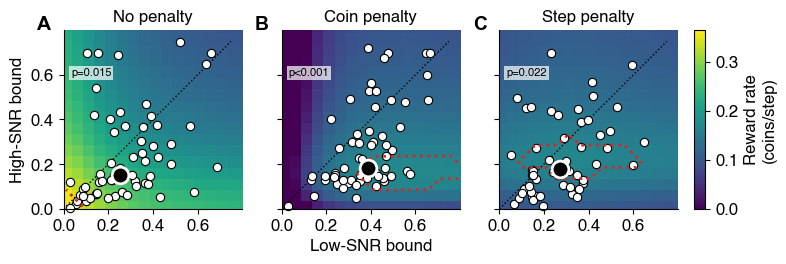

Saved /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Figures/Figure05_S03.pdf (+ .png)


In [4]:
use_figure_style()
WID, PSW, CBAR_W, CBAR_PAD = 15.6, 1.0, 0.3, 0.4   # cm, as in Figure05
PANEL = (WID - 2 * PSW) / 3
fig_w = WID + CBAR_PAD + CBAR_W
fig = plt.figure(figsize=(fig_w * CM, PANEL * CM))
gs = gridspec.GridSpec(1, 3, figure=fig, left=0, right=WID / fig_w, bottom=0, top=1, wspace=PSW / PANEL)
axs = [fig.add_subplot(gs[0, c]) for c in range(3)]

vmax = max(m.max() for m in rr_matrices.values())
half = (RR_BOUNDS[1] - RR_BOUNDS[0]) / 2
extent = [RR_BOUNDS[0] - half, RR_BOUNDS[-1] + half, RR_BOUNDS[0] - half, RR_BOUNDS[-1] + half]
lo_grid, hi_grid = np.meshgrid(RR_BOUNDS, RR_BOUNDS)

for c, b in enumerate(BLOCKS):
    ax = axs[c]
    rm = rr_matrices[b]
    im = ax.imshow(rm, origin='lower', extent=extent, aspect='auto', vmin=0, vmax=vmax, cmap='viridis', zorder=0)
    ax.plot([0, 0.75], [0, 0.75], 'k:', lw=1, zorder=1)

    lo, hi = bounds[b]
    valid = np.isfinite(lo) & np.isfinite(hi)
    # Bounds beyond the panel are drawn at the edge as triangles pointing off-scale.
    plot_subject_points(ax, np.where(valid, lo, np.nan), np.where(valid, hi, np.nan), xlim=(0, X_SHOW_MAX),
                        ylim=(0, X_SHOW_MAX), zorder=2, ms=HEATMAP_MARKER_SIZE)
    # Near-optimal region (>= 95% of the panel's own maximum), above the participants
    ax.contour(lo_grid, hi_grid, (rm >= 0.95 * rm.max()).astype(float), levels=[0.5], colors=OPTIMAL_COLOR,
               linewidths=2, linestyles=':', zorder=3)
    ax.plot(np.median(lo[valid]), np.median(hi[valid]), **MEDIAN_MARKER, zorder=5)
    _, p = scipy.stats.wilcoxon(lo[valid], hi[valid])
    ax.text(0.04, 0.79, format_p(p), transform=ax.transAxes, ha='left', va='top', fontsize=FS_INSET, zorder=1.5,
            bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', pad=1.5))

    ax.set_xlim(0, X_SHOW_MAX + 0.02)
    ax.set_ylim(0, X_SHOW_MAX + 0.02)
    ax.set_xticks([0, 0.2, 0.4, 0.6])
    ax.set_yticks([0, 0.2, 0.4, 0.6])
    ax.set_aspect('equal')
    ax.set_title(CONDITION_LABELS[b])
    if c == 0:
        ax.set_ylabel('High-SNR bound')
    else:
        ax.tick_params(axis='y', labelleft=False)
    if c == 1:
        ax.set_xlabel('Low-SNR bound')
    ax.spines[['top', 'right']].set_visible(False)
    add_panel_label(ax, 'ABC'[c])

y0, y1 = axs[0].get_position().y0, axs[0].get_position().y1
cax = fig.add_axes([(WID + CBAR_PAD) / fig_w, y0, CBAR_W / fig_w, y1 - y0])
cbar = fig.colorbar(im, cax=cax)
cbar.set_label('Reward rate\n(coins/step)')

out = FIGURES_DIR / 'Figure05_S03.pdf'
fig.savefig(out, dpi=300, bbox_inches='tight')
fig.savefig(out.with_suffix('.png'), dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved {out} (+ .png)')

## Statistics

Per panel: median [IQR] of hi − lo and of hi / lo, the Wilcoxon signed-rank p of hi − lo (as in the panels), the
Spearman correlation of lo and hi, and the range of near-optimal low- and high-SNR bounds.

In [5]:
rows = []
for b in BLOCKS:
    lo, hi = bounds[b]
    valid = np.isfinite(lo) & np.isfinite(hi) & (lo > 0)
    lo, hi = lo[valid], hi[valid]
    diff, ratio = hi - lo, hi / lo
    rho, p_rho = scipy.stats.spearmanr(lo, hi)
    hi_idx, lo_idx = np.nonzero(rr_matrices[b] >= 0.95 * rr_matrices[b].max())
    rows.append({'Panel': 'ABC'[b - 1], 'Condition': CONDITION_LABELS[b], 'n': int(valid.sum()),
                 'Median hi − lo [IQR]': f'{np.median(diff):.3f} [{np.percentile(diff, 25):.3f}, {np.percentile(diff, 75):.3f}]',
                 'p (hi − lo)': format_p(scipy.stats.wilcoxon(lo, hi).pvalue),
                 'Median hi / lo [IQR]': f'{np.median(ratio):.3f} [{np.percentile(ratio, 25):.3f}, {np.percentile(ratio, 75):.3f}]',
                 'Spearman lo vs. hi': f'{format_rho(rho, 3)}, {format_p(p_rho)}',
                 'Near-optimal lo': f'{RR_BOUNDS[lo_idx].min():.2f}-{RR_BOUNDS[lo_idx].max():.2f}',
                 'Near-optimal hi': f'{RR_BOUNDS[hi_idx].min():.2f}-{RR_BOUNDS[hi_idx].max():.2f}'})
pd.DataFrame(rows)

,Panel,Condition,n,Median hi − lo [IQR],p (hi − lo),Median hi / lo [IQR],Spearman lo vs. hi,Near-optimal lo,Near-optimal hi
0,A,No penalty,59,"-0.062 [-0.164, 0.013]",p=0.015,"0.669 [0.405, 1.045]","ρ=0.461, p<0.001",0.01-0.06,0.01-0.06
1,B,Coin penalty,59,"-0.111 [-0.222, -0.005]",p<0.001,"0.657 [0.398, 0.972]","ρ=0.534, p<0.001",0.36-0.81,0.11-0.21
2,C,Step penalty,54,"-0.067 [-0.144, 0.028]",p=0.022,"0.714 [0.391, 1.100]","ρ=0.394, p=0.003",0.11-0.61,0.16-0.31
